# Complexity-04d — Secrétaire matroïdal : mesure élément par élément

[Source Python](Complexity-04d-Secretaire-Matroidal-Python.ipynb) · [04b](Complexity-04b-OnlineConjectures-Secretary-KServer-Python.ipynb) · [Index](README.md)

**Objectifs** : manipuler trois oracles, calculer l'optimum glouton, simuler l'algorithme décrit par le source et mesurer les fréquences d'acceptation. **Prérequis** : ensembles et ordre aléatoire. **Durée pédagogique** : 40 minutes.

Le carnet Python versionné est la source consultée pour cette transposition native C#. L'énoncé attribué à Singla y est présenté comme une annonce de prépublication ; sa preuve n'a pas été lue ici. Les échantillons .NET, reproductibles par graine, ne sont pas ceux de Python.

In [1]:
using System;
using System.Linq;
using System.Collections.Generic;
using System.Numerics;
using System.Globalization;
CultureInfo.DefaultThreadCurrentCulture = CultureInfo.InvariantCulture;
CultureInfo.DefaultThreadCurrentUICulture = CultureInfo.InvariantCulture;
Console.WriteLine("Structures et générateur .NET prêts");

The below script needs to be able to find the current output cell; this is an easy method to get it.

Structures et générateur .NET prêts


## 1. Trois oracles et optimum hors ligne

Un ensemble est indépendant s'il respecte le rang uniforme, les quotas de partition ou l'acyclicité graphique. Sur un matroïde à poids positifs, le glouton décroissant donne l'optimum hors ligne.

In [2]:
int[] Permutation(int n, Random r) {
    int[] p=Enumerable.Range(0,n).ToArray();
    for(int i=n-1;i>0;i--) { int j=r.Next(i+1); (p[i],p[j])=(p[j],p[i]); }
    return p;
}
Func<IEnumerable<int>,bool> Uniforme(int rang) => s=>s.Count()<=rang;
Func<IEnumerable<int>,bool> Partition(int[] classes,int[] quotas) => s=>s.GroupBy(i=>classes[i]).All(g=>g.Count()<=quotas[g.Key]);
Func<IEnumerable<int>,bool> Graphique(int n,(int,int)[] aretes) => s=> {
    int[] parent=Enumerable.Range(0,n).ToArray();
    int Racine(int x) { while(parent[x]!=x) x=parent[x]; return x; }
    foreach(int e in s) { var(a,b)=aretes[e]; int ra=Racine(a),rb=Racine(b); if(ra==rb) return false; parent[ra]=rb; }
    return true;
};
HashSet<int> Glouton(double[] valeurs,Func<IEnumerable<int>,bool> ind) {
    var choix=new HashSet<int>();
    foreach(int i in Enumerable.Range(0,valeurs.Length).Where(i=>valeurs[i]>0).OrderByDescending(i=>valeurs[i]).ThenBy(i=>i))
        if(ind(choix.Append(i))) choix.Add(i);
    return choix;
}
var valeurs=new[]{5.0,1.0,4.0,3.0,0.5,2.0,4.5,0.2};
var classes=new[]{0,0,0,1,1,1,2,2}; var quotas=new[]{1,2,1};
var aretes=new[]{(0,1),(0,2),(1,2),(1,3),(2,3),(2,4),(3,4),(0,4)};
var instances=new (string nom,Func<IEnumerable<int>,bool> ind)[]{
    ("uniforme k=1",Uniforme(1)),("uniforme k=2",Uniforme(2)),("uniforme k=3",Uniforme(3)),("uniforme k=4",Uniforme(4)),
    ("partition",Partition(classes,quotas)),("graphique",Graphique(5,aretes))};
foreach(var (nom,ind) in instances) { var opt=Glouton(valeurs,ind); Console.WriteLine($"{nom} : OPT {{{string.Join(",",opt.OrderBy(i=>i))}}}, valeur {opt.Sum(i=>valeurs[i]):F1}"); }
Console.WriteLine($"Partition {{0,1}} indépendante : {Partition(classes,quotas)(new[]{0,1})}");

uniforme k=1 : OPT {0}, valeur 5.0


uniforme k=2 : OPT {0,6}, valeur 9.5


uniforme k=3 : OPT {0,2,6}, valeur 13.5


uniforme k=4 : OPT {0,2,3,6}, valeur 16.5


partition : OPT {0,3,5,6}, valeur 14.5


graphique : OPT {0,2,3,6}, valeur 16.5


Partition {0,1} indépendante : False


Les mêmes huit poids et les mêmes arêtes sont employés dans toutes les comparaisons. La partition interdit par exemple deux éléments de la première classe.

## 2. Ordre virtuel entrelacé

À chaque essai, on mélange l'arrivée, on tire K selon Bin(n, 1/2), puis on replace les K éléments échantillons dans K positions aléatoires de l'ordre virtuel. Le glouton compare les configurations avant et après la proposition sur les éléments déjà finalisés.

In [3]:
HashSet<int> Singla(double[] v,Func<IEnumerable<int>,bool> ind,Random r) {
    int n=v.Length; var arrivee=Permutation(n,r); int k=Enumerable.Range(0,n).Count(_=>r.NextDouble()<0.5);
    var echantillon=arrivee.Take(k).ToHashSet();
    var marques=Permutation(n,r).Take(k).ToHashSet();
    int ia=0,ib=k; int[] virtuel=new int[n];
    for(int p=0;p<n;p++) virtuel[p]=marques.Contains(p)?arrivee[ia++]:arrivee[ib++];
    var w=Enumerable.Range(0,n).Select(i=>echantillon.Contains(i)?v[i]:0.0).ToArray();
    var acceptes=new HashSet<int>(); var finalises=new HashSet<int>();
    foreach(int e in virtuel) {
        var propose=(double[])w.Clone(); propose[e]=echantillon.Contains(e)?0:v[e];
        var avant=Glouton(w,ind); var apres=Glouton(propose,ind);
        if(avant.Intersect(finalises).ToHashSet().SetEquals(apres.Intersect(finalises))) {
            if(apres.Contains(e)) acceptes.Add(e);
            w=propose;
        }
        finalises.Add(e);
    }
    acceptes.ExceptWith(echantillon); return acceptes;
}
(HashSet<int> opt,Dictionary<int,double> freq,double moyenne) Banc(double[] v,Func<IEnumerable<int>,bool> ind,int essais=4000,int seed=7) {
    var r=new Random(seed); var opt=Glouton(v,ind); var compte=opt.ToDictionary(e=>e,e=>0); double somme=0;
    for(int i=0;i<essais;i++) { var choix=Singla(v,ind,r); foreach(int e in opt) if(choix.Contains(e)) compte[e]++; somme+=choix.Sum(e=>v[e]); }
    return (opt,compte.ToDictionary(kv=>kv.Key,kv=>(double)kv.Value/essais),somme/essais);
}
var demo=Singla(valeurs,Uniforme(3),new Random(1));
Console.WriteLine($"Exemple rang 3 : {{{string.Join(",",demo.OrderBy(i=>i))}}}, valeur {demo.Sum(i=>valeurs[i]):F1}");

Exemple rang 3 : {0,2,3}, valeur 12.0


L'entrelacement est aléatoire : placer tous les éléments échantillonnés en tête changerait l'algorithme. Le retour exclut les éléments réservés à l'échantillon.

## 3. Banc de garantie

Le notebook Python rapporte l'annonce suivante : pour tout élément e de l'optimum hors ligne, la probabilité que l'algorithme accepte e est au moins 1/4, pour un matroïde accessible par oracle et des valeurs positives. Par linéarité de l'espérance, sommer les poids multipliés par leurs probabilités d'acceptation donne E[ALG] ≥ OPT/4. La garantie élément par élément est plus forte que ce seul ratio, qui pourrait masquer un élément rarement accepté.

Le banc conserve six instances, quatre rangs uniformes, une partition et un graphique, avec 4 000 essais par instance. Il mesure chaque fréquence et le ratio de valeur moyen. Les fluctuations sont visibles ; une estimation voisine du repère ne démontre ni la garantie universelle ni que la borne est serrée. Le source explique qu'un ancien ordre virtuel sans entrelacement produisait une fréquence sous 1/4 : une garantie peut donc aider à déceler une erreur d'implémentation, sans prouver à elle seule sa correction.

In [4]:
var resultats=new Dictionary<string,(HashSet<int> opt,Dictionary<int,double> freq,double moyenne)>();
foreach(var (nom,ind) in instances) {
    var b=Banc(valeurs,ind); resultats[nom]=b;
    Console.WriteLine($"{nom,-14} OPT={b.opt.Sum(i=>valeurs[i]),5:F1}, min fréquence={b.freq.Values.Min():F3}, E[ALG]/OPT={b.moyenne/b.opt.Sum(i=>valeurs[i]):F3} : {string.Join(" ",b.freq.OrderBy(k=>k.Key).Select(k=>$"{k.Key}:{k.Value:F3}"))}");
}
Console.WriteLine("Six instances, 4000 essais par instance ; fluctuations d'échantillonnage présentes");

uniforme k=1   OPT=  5.0, min fréquence=0.257, E[ALG]/OPT=0.446 : 0:0.257


uniforme k=2   OPT=  9.5, min fréquence=0.265, E[ALG]/OPT=0.422 : 0:0.265 6:0.270


uniforme k=3   OPT= 13.5, min fréquence=0.305, E[ALG]/OPT=0.424 : 0:0.314 2:0.305 6:0.306


uniforme k=4   OPT= 16.5, min fréquence=0.376, E[ALG]/OPT=0.457 : 0:0.384 2:0.376 3:0.377 6:0.389


partition      OPT= 14.5, min fréquence=0.311, E[ALG]/OPT=0.449 : 0:0.311 3:0.444 5:0.433 6:0.375


graphique      OPT= 16.5, min fréquence=0.364, E[ALG]/OPT=0.452 : 0:0.386 2:0.364 3:0.385 6:0.393


Six instances, 4000 essais par instance ; fluctuations d'échantillonnage présentes


La borne affichée sert de repère pour les fréquences, et le ratio moyen agrège les poids ; ce sont deux mesures différentes.

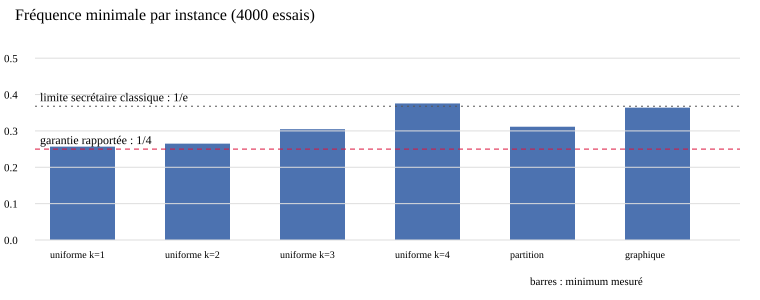

In [5]:
using Microsoft.DotNet.Interactive.Formatting;
record Svg(string Content);
Formatter.Register<Svg>((v,w)=>w.Write(v.Content),"image/svg+xml");
Formatter.SetPreferredMimeTypesFor(typeof(Svg),"image/svg+xml");
var barres=instances.Select((x,i)=>(x.nom, minimum:resultats[x.nom].freq.Values.Min(),i)).ToArray();
var svg=new System.Text.StringBuilder();
svg.Append("<svg xmlns='http://www.w3.org/2000/svg' width='760' height='300' viewBox='0 0 760 300'><rect width='760' height='300' fill='white'/><text x='15' y='20' font-size='16'>Fréquence minimale par instance (4000 essais)</text>");
foreach(var (nom,v,i) in barres) {
    double x=50+i*115, hauteur=200*v/0.55;
    svg.Append($"<rect x='{x}' y='{240-hauteur}' width='65' height='{hauteur}' fill='#4c72b0'/><text x='{x}' y='258' font-size='10'>{System.Net.WebUtility.HtmlEncode(nom)}</text>");
}
for(int tick=0;tick<=5;tick++) { double v=tick/10.0, yy=240-200*v/0.55;
    svg.Append($"<line x1='35' y1='{yy}' x2='740' y2='{yy}' stroke='#dddddd'/><text x='4' y='{yy+4}' font-size='11'>{v:F1}</text>"); }
double y=240-200*0.25/0.55;
svg.Append($"<line x1='35' y1='{y}' x2='740' y2='{y}' stroke='crimson' stroke-dasharray='5 4'/><text x='40' y='{y-5}' font-size='12'>garantie rapportée : 1/4</text>");
double yE=240-200*(1/Math.E)/0.55;
svg.Append($"<line x1='35' y1='{yE}' x2='740' y2='{yE}' stroke='#555' stroke-dasharray='2 4'/><text x='40' y='{yE-5}' font-size='12'>limite secrétaire classique : 1/e</text><text x='530' y='285' font-size='11'>barres : minimum mesuré</text></svg>");
display(new Svg(svg.ToString()));

La ligne rouge matérialise le repère 1/4. Les hauteurs viennent des sorties de la cellule précédente et restent soumises au bruit des 4 000 essais.

## Exercice 1 — Le goulot de la partition

Faire varier de 1 à 3 le quota de la première classe, mesurer 4 000 exécutions par quota et rendre le minimum des fréquences des éléments de l'optimum. Comparer les résultats sans supposer une monotonie théorique.

In [6]:
Dictionary<int,double> EffetQuota(int essais=4000) {
    // TODO : utiliser Banc pour chaque quota, puis prendre le minimum des fréquences.
    return null;
}
var ex1=EffetQuota(4000);
if(ex1==null) Console.WriteLine("Exercice 1 à compléter");
else {
    if(ex1.Count!=3 || ex1.Keys.Any(q=>q<1 || q>3) || ex1.Values.Any(v=>!double.IsFinite(v) || v<0 || v>1)) throw new Exception("Quotas ou fréquences invalides");
    foreach(int q in new[]{1,2,3}) {
        var attendu=Banc(valeurs,Partition(classes,new[]{q,2,1}),4000).freq.Values.Min();
        if(!ex1.ContainsKey(q) || Math.Abs(ex1[q]-attendu)>1e-12) throw new Exception("Fréquence minimale incorrecte pour le quota");
    }
    Console.WriteLine("Trois quotas comparés au banc reproductible, 4000 essais chacun");
    var qsvg=new System.Text.StringBuilder("<svg xmlns='http://www.w3.org/2000/svg' width='480' height='260'><rect width='480' height='260' fill='white'/><text x='15' y='20'>Minimum de fréquence selon quota</text>");
    foreach(int q in new[]{1,2,3}) { double h=180*ex1[q]; qsvg.Append($"<rect x='{50+q*100}' y='{220-h}' width='55' height='{h}' fill='#4c72b0'/><text x='{60+q*100}' y='240'>quota {q}</text>"); }
    qsvg.Append("</svg>"); display(new Svg(qsvg.ToString()));
}

Exercice 1 à compléter


## Exercice 2 — Approcher 1/4

Construire une instance de 10 éléments au plus, avec un des trois oracles, puis examiner la plus petite fréquence de l'optimum. Discuter le bruit statistique avant de comparer à 1/4.

In [7]:
(double[],Func<IEnumerable<int>,bool>)? InstancePresqueUnQuart() {
    // TODO : renvoyer une instance et son oracle.
    return null;
}
var ex2=InstancePresqueUnQuart();
if(ex2==null) Console.WriteLine("Exercice 2 à compléter");
else {
    var (v,ind)=ex2.Value;
    if(v==null || ind==null || v.Length<2 || v.Length>10 || v.Any(x=>x<=0) || !ind(Array.Empty<int>()) || Glouton(v,ind).Count==0)
        throw new Exception("Instance ou oracle invalide");
    var b=Banc(v,ind,4000,7);
    Console.WriteLine($"Minimum mesuré {b.freq.Values.Min():F3} ; comparer avec prudence au bruit des 4000 essais");
}

Exercice 2 à compléter


## 4. Le secrétaire classique comme point de comparaison

Pour n=8, le seuil arrondi à n/e observe trois personnes. La formule finie du succès est distincte de sa limite asymptotique 1/e. Le même banc emploie 4 000 tirages.

Sur le rang 1 de huit éléments, le seuil dédié et l'algorithme universel sont comparés sur le même ensemble de poids. La formule finie du seuil vaut (k/n) Σ_{i=k+1}^n 1/(i−1) avec k=3 ; 1/e est sa limite asymptotique, pas cette probabilité finie. Les six ratios E[ALG]/OPT sont calculés à partir des fréquences de ces mêmes expériences.

In [8]:
int? Classique(double[] v,Random r) {
    int n=v.Length, obs=Math.Max(1,(int)Math.Round(n/Math.E)); var ordre=Permutation(n,r);
    double seuil=ordre.Take(obs).Max(i=>v[i]);
    foreach(int i in ordre.Skip(obs)) if(v[i]>seuil) return i;
    return null;
}
var rcmp=new Random(11); int succes=0;
for(int i=0;i<4000;i++) if(Classique(valeurs,rcmp)==0) succes++;
double exacte=3.0/8*Enumerable.Range(4,5).Sum(i=>1.0/(i-1));
Console.WriteLine($"Classique n=8 : {succes/4000.0:F3}; formule finie={exacte:F3}, limite=1/e={1/Math.E:F3}");
Console.WriteLine($"Singla rang 1 : fréquence du meilleur={resultats["uniforme k=1"].freq[0]:F3}; repère 1/4");
Console.WriteLine($"Moyenne des six ratios E[ALG]/OPT : {instances.Average(x=>resultats[x.nom].moyenne/resultats[x.nom].opt.Sum(i=>valeurs[i])):F3}");

Classique n=8 : 0.415; formule finie=0.410, limite=1/e=0.368


Singla rang 1 : fréquence du meilleur=0.257; repère 1/4


Moyenne des six ratios E[ALG]/OPT : 0.442


La comparaison juxtapose deux méthodes sur une instance particulière. Une différence empirique ne mesure pas à elle seule un prix universel.

## Exercice 3 — Deux places et événements conjoints

L'ordre de passage est fourni explicitement comme permutation d'indices, pour distinguer les règles de sélection du tirage aléatoire. Observer les premiers `round(n/e)` candidats, puis accepter les valeurs qui dépassent le maximum observé, dans la limite de deux places.

Pour `dernier`, si une place reste libre, accepter le dernier candidat. Pour `deux_derniers`, accepter en outre tout candidat lorsque le nombre de candidats restant à passer égale le nombre de places libres : cela remplit les deux places dès que possible en fin de séquence. Chaque décision utilise uniquement le préfixe révélé. Comparer les probabilités d'accepter les deux meilleurs sur 4 000 permutations, puis mesurer directement l'intersection pour Singla. Multiplier les marginales suppose une indépendance non établie.

In [9]:
HashSet<int> SecretaireDeux(double[] v,int[] ordre,string rattrapage) {
    // TODO : appliquer la règle du seuil et la politique de rattrapage au fil de l'ordre.
    return null;
}
var testOrdre=new[]{0,1,2,3,4,5};
var ex3=SecretaireDeux(new[]{6.0,5,1,2,3,4},testOrdre,"dernier");
if(ex3==null) Console.WriteLine("Exercice 3 à compléter");
else {
    var attendus=new[]{
        (new[]{6.0,5,1,2,3,4}, "dernier", new[]{5}),
        (new[]{6.0,5,1,2,3,4}, "deux_derniers", new[]{4,5}),
        (new[]{1.0,2,3,6,5,4}, "dernier", new[]{2,3}),
        (new[]{1.0,2,3,6,5,4}, "deux_derniers", new[]{2,3})};
    foreach(var (v,mode,attendu) in attendus) {
        var resultat=SecretaireDeux(v,testOrdre,mode);
        if(resultat==null || !resultat.SetEquals(attendu)) throw new Exception("Sélection incorrecte sur ordre connu ou rattrapage");
    }
    foreach(string mode in new[]{"dernier","deux_derniers"}) {
        var r=new Random(7); int joints=0;
        for(int i=0;i<4000;i++) { var s=SecretaireDeux(valeurs,Permutation(valeurs.Length,r),mode);
            if(s==null || s.Count>2 || s.Any(x=>x<0 || x>=valeurs.Length)) throw new Exception("Sélection invalide");
            if(s.Contains(0) && s.Contains(6)) joints++; }
        Console.WriteLine($"{mode} : P(deux meilleurs)={joints/4000.0:F3} (4000 essais)");
    }
    var rs=new Random(31); int ensemble=0;
    for(int i=0;i<4000;i++) { var s=Singla(valeurs,Uniforme(2),rs); if(s.Contains(0) && s.Contains(6)) ensemble++; }
    Console.WriteLine($"Singla rang 2 : P(deux meilleurs ensemble)={ensemble/4000.0:F3} (4000 essais)");
}

Exercice 3 à compléter


## À retenir

- Les oracles uniforme, de partition et graphique exposent la même interface d'indépendance.
- Les fréquences individuelles, le ratio moyen et la probabilité conjointe répondent à des questions différentes.
- Le banc est fini : il vérifie des calculs et ne démontre pas la garantie générale annoncée dans la source.

## Vérifiez votre compréhension

1. Pourquoi l'ordre virtuel doit-il entrelacer l'échantillon ?
2. Pourquoi la fréquence minimale diffère-t-elle du ratio en espérance ?
3. Peut-on multiplier deux fréquences pour obtenir leur intersection ?

<details><summary>Éléments de réponse</summary>

1. L'entrelacement fait partie du procédé décrit. 2. Le ratio pondère les gains par les valeurs. 3. Seulement sous indépendance ; ici il faut mesurer l'événement joint.
</details>

## Pour aller plus loin

[Source Python](Complexity-04d-Secretaire-Matroidal-Python.ipynb) et [04b](Complexity-04b-OnlineConjectures-Secretary-KServer-Python.ipynb). Les références historiques et la prépublication sont rapportées par le source Python ; aucune lecture directe de ces documents n'est revendiquée ici.

**Références rapportées par le source Python** : Singla, *The Matroid Secretary Conjecture is True* ; Babaioff, Immorlica et Kleinberg, *Matroids, secretary problems, and online mechanisms* ; Lindley et Dynkin sur le secrétaire classique. Ces publications n'ont pas été consultées pour ce port.